# 1. 설치 확인

In [3]:
import huggingface_hub
huggingface_hub.__version__

'2.2.0'

# 2. huggingface 로그인

## 토큰 사용해서 로그인

In [4]:
from huggingface_hub import login
login()
print('로그인 성공')

로그인 성공


# 3. 모델 다운로드

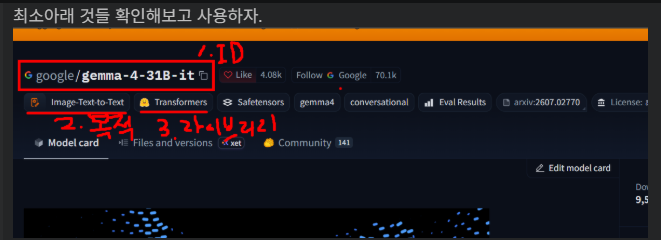

## 3-1. 전체 파일 다운로드

In [8]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id = 'good593/gemma3-finetune-diseases-gguf',
    cache_dir = './custom_models'
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

c:\dev\study_study\hugging face\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\dev\study_study\hugging face\custom_models. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\dev\study_study\hugging face\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-s

'C:\\dev\\study_study\\hugging face\\custom_models\\models--good593--gemma3-finetune-diseases-gguf\\snapshots\\c54eba361ec2ba4ef5f3d9769ae025a1efd115fa'

## 3-2. 특정 파일 다운로드

In [10]:
from huggingface_hub import hf_hub_download

hf_hub_download(
    repo_id = 'google/embeddinggemma-2',
    filename = 'config.json',
    local_dir = './custom_models'
)



config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

'C:\\dev\\study_study\\hugging face\\custom_models\\config.json'

# 4. 허깅페이스 안의 모델 조회하기

In [11]:
from huggingface_hub import list_models

search_models = list_models(
    filter = 'text-generation',\
    limit = 5
)

In [14]:
for model in search_models:
    print(f"{model.id} & {model.downloads}")

jialinyyzz/humanizer & 103709
LiquidAI/LFM2.5-24B-A2B & 13007
ConwayResearch/Underdog-Saluki-27B-1.0 & 410558
LiquidAI/LFM2.5-24B-A2B-GGUF & 107599


# 5. 모델 저장소 생성하기 (나만의 모델만들어서 올리기)

In [15]:
from huggingface_hub import HfApi

api = HfApi()

try:
    huggingface_id = 'coconut-juice99'

    new_repo_id = f'{huggingface_id}/my_first_model'
    api.create_repo(
        repo_id = new_repo_id,
        private = True
    )

except Exception as e:
    print(f'오류가 발생했어요>{e}')

# 6. 생성된 모델 저장소에 파일 업로드

In [17]:
from huggingface_hub import upload_file

upload_file(
    path_or_fileobj = './custom_models/config.json', #업로드할 파일/폴더
    path_in_repo = 'new_config.json', #저장소에 저장될 이름
    repo_id=new_repo_id, #저장소 아이디
    commit_message='코딩 좋아'
)

CommitInfo(commit_url='https://huggingface.co/coconut-juice99/my_first_model/commit/d2b61eb9ae7a5ad0e37b409b9d1e1f75f94bc6c4', commit_message='코딩 좋아', commit_description='', oid='d2b61eb9ae7a5ad0e37b409b9d1e1f75f94bc6c4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/coconut-juice99/my_first_model', endpoint='https://huggingface.co', repo_type='model', repo_id='coconut-juice99/my_first_model'), pr_revision=None, pr_num=None)

# 7.저장소 삭제

In [18]:
try:
    api.delete_repo(
        repo_id = new_repo_id
    )
    
except Exception as e:
    print('오류발생!!!!')